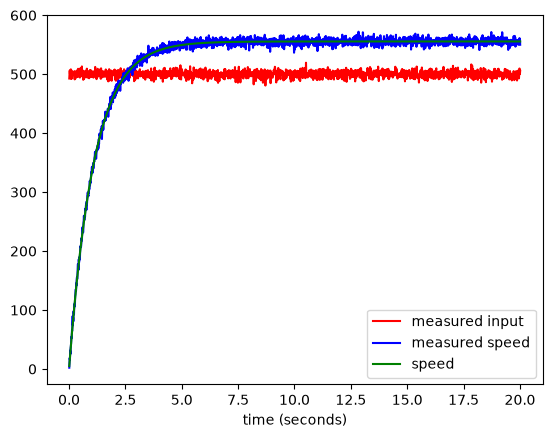

In [5]:

import random
import arslabrobotics as ar

cart = ar.system.Cart(1.0, 0.9)

dp = ar.data.DataPlotter()
dp.set_x("time (seconds)")
dp.add_y("measure_in", "measured input")
dp.add_y("measure", "measured speed")
dp.add_y("speed", "speed")

f = 500.0

data_file = open("cart_data.txt", "w")

t = ar.utils.Time(use_fake_time = True)

t.start()
while t.get() < 20:
    t.sleep(0.01)
    delta_t = t.elapsed()
    (p, v) = cart.evaluate(delta_t, f)
    
    dp.append_x(t.get())
    dp.append_y("speed", v)

    fn = f + random.gauss(0, 5)
    vn = v + random.gauss(0, 5)
    
    dp.append_y("measure", vn)
    dp.append_y("measure_in", fn)
    
    data_file.write(f"{fn} {vn}\n")

dp.plot()
data_file.close()
